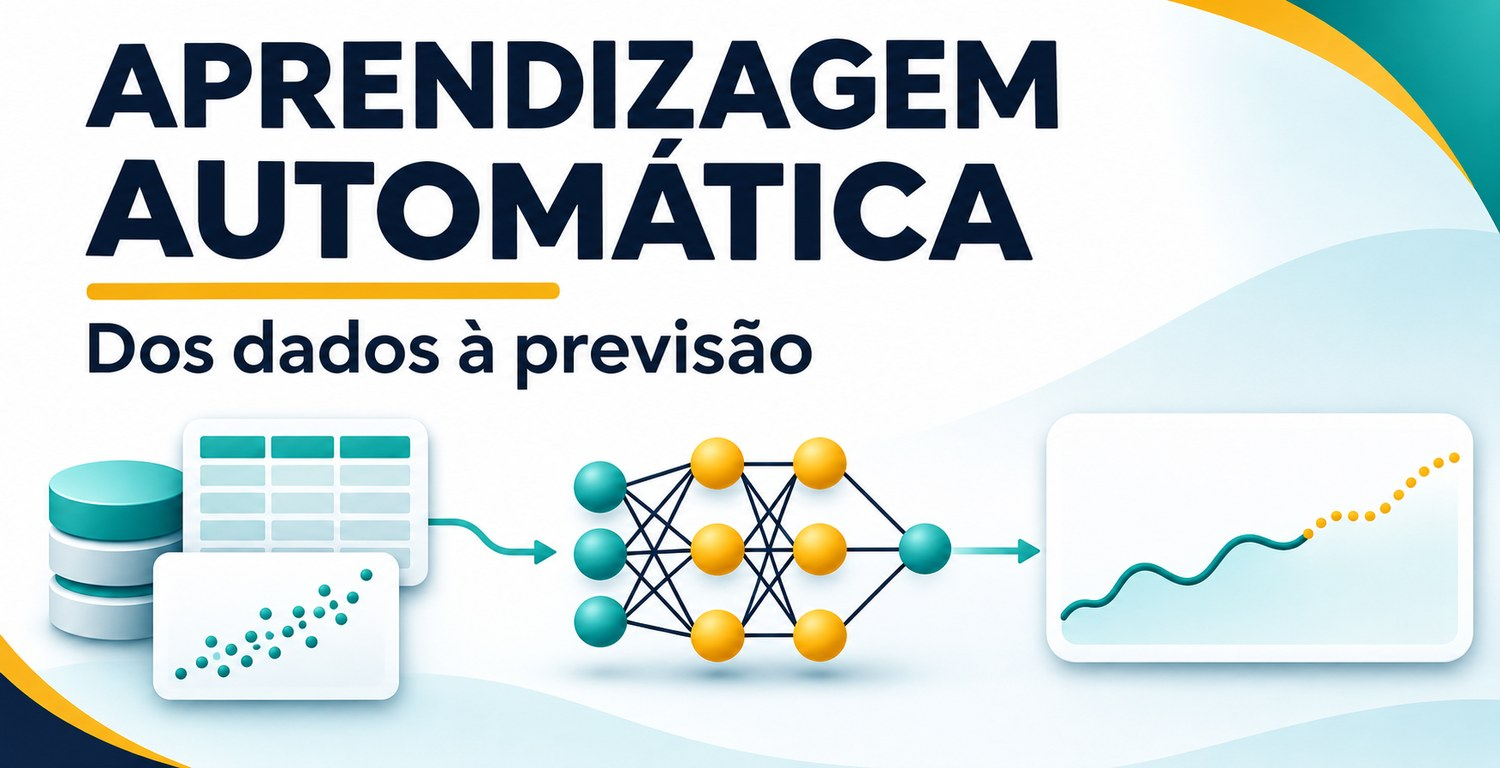

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Aprendizagem%20Autom%C3%A1tica/tutorial_machine_learning/modulo_1_aprender_com_dados/02_IA_Aprendizagem_e_Tipos.ipynb)

# Capítulo 2 – Inteligência artificial, aprendizagem automática e os tipos de aprendizagem

«Inteligência artificial», «aprendizagem automática» (*machine learning*) e «aprendizagem profunda» (*deep learning*) usam-se muitas vezes como sinónimos, e não são. Este capítulo arruma os três termos, compara-os no mesmo problema e percorre os tipos de aprendizagem. Dois deles já conheces. O terceiro, a aprendizagem por reforço, é novo, e vamos implementá-lo de raiz na sua forma mais simples.

> **Objetivos:** distinguir inteligência artificial, aprendizagem automática e aprendizagem profunda; resolver o mesmo problema com regras, com um modelo clássico e com uma rede neuronal, e comparar; reconhecer aprendizagem supervisionada, não supervisionada e por reforço a partir dos dados disponíveis; explicar o dilema entre explorar e aproveitar; implementar a estratégia ε-gulosa.

**Pré-requisitos:** capítulo 1 deste módulo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

Continuamos com os lotes do lagar (dados sintéticos).

In [2]:
def gerar_lotes(n=900, semente=7):
    """Gera lotes de azeitona entregues num lagar fictício (dados sintéticos; as medições são inventadas)."""
    rng = np.random.default_rng(semente)
    # variedade: peso médio do fruto (g), comprimento (mm), razão comprimento/largura, rendimento de base (%)
    perfis = {"Galega": (2.4, 17.5, 1.42, 15.5), "Cobrançosa": (4.3, 22.0, 1.33, 18.5), "Cordovil": (5.0, 23.0, 1.22, 20.0)}
    variedade = rng.choice(list(perfis), n, p=[0.45, 0.33, 0.22])
    base = np.array([perfis[v] for v in variedade])
    peso = np.clip(rng.normal(base[:, 0], 0.55), 1.0, None)
    comprimento = base[:, 1] + 2.2 * (peso - base[:, 0]) + rng.normal(0, 1.1, n)
    largura = comprimento / base[:, 2] + rng.normal(0, 0.5, n)
    maturacao = np.clip(rng.normal(3.4, 1.2, n), 0, 7)
    humidade = np.clip(rng.normal(52 - 1.5 * (maturacao - 3.4), 4), 38, 66)
    rendimento = base[:, 3] + 1.1 * (maturacao - 3.4) - 0.28 * (humidade - 52) + rng.normal(0, 1.0, n)
    return pd.DataFrame({
        "lote_id": [f"L{i:04d}" for i in range(1, n + 1)],
        "variedade": variedade,
        "peso_g": peso.round(2),
        "comprimento_mm": comprimento.round(1),
        "largura_mm": largura.round(1),
        "maturacao": maturacao.round(1),
        "humidade_pct": humidade.round(1),
        "rendimento_pct": rendimento.round(1),
    })


lotes = gerar_lotes()
print(lotes.shape)
lotes.head()

(900, 8)


,lote_id,variedade,peso_g,comprimento_mm,largura_mm,maturacao,humidade_pct,rendimento_pct
0,L0001,Cobrançosa,4.24,21.3,15.7,3.1,53.2,17.9
1,L0002,Cordovil,5.25,22.5,18.3,6.3,48.3,25.7
2,L0003,Cobrançosa,4.71,23.9,17.5,3.0,52.5,18.3
3,L0004,Galega,2.16,15.8,10.4,2.0,57.2,11.5
4,L0005,Galega,2.57,15.5,10.2,3.4,44.4,17.0


## Três termos, uns dentro dos outros

- **Inteligência artificial (IA)** é a área mais larga: sistemas que executam tarefas que associamos a inteligência, como planear, procurar, jogar, reconhecer ou decidir. Muita IA **não aprende** com dados: um programa que encontra o caminho mais curto num mapa ou que resolve um horário com restrições segue um algoritmo escrito por uma pessoa.
- **Aprendizagem automática (AA)** é a parte da IA em que as regras são **ajustadas a partir de exemplos**. É o assunto deste tutorial.
- **Aprendizagem profunda (AP)** é a parte da aprendizagem automática que usa redes neuronais com muitas camadas. É a abordagem dominante em imagem, som e texto, onde os atributos úteis não vêm numa tabela e têm de ser aprendidos.

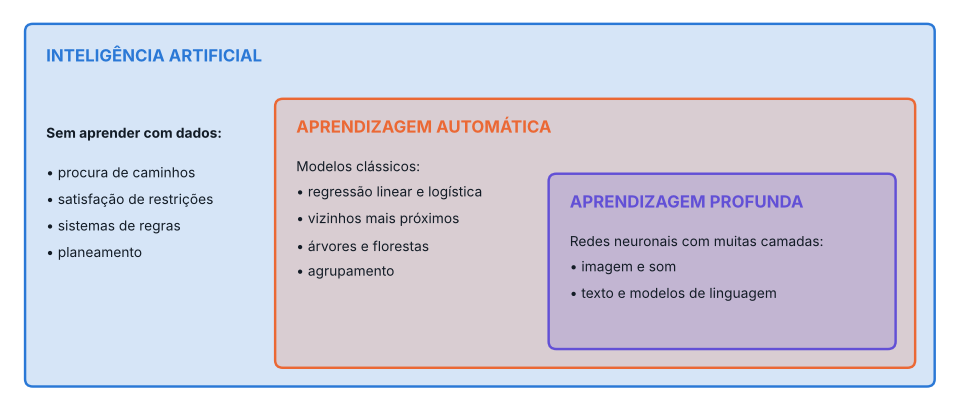

In [3]:
fig, ax = tela(12, 5.2, (11, 4.6))
caixa(ax, 0.2, 0.2, 11.6, 4.8, "", AZUL)
caixa(ax, 3.4, 0.45, 8.15, 3.55, "", LARANJA)
caixa(ax, 6.9, 0.7, 4.4, 2.3, "", VIOLETA)
ax.text(0.45, 4.6, "INTELIGÊNCIA ARTIFICIAL", fontweight="bold", color=AZUL, fontsize=11, va="center")
ax.text(0.45, 3.5, "Sem aprender com dados:", fontsize=9, color=TINTA, fontweight="bold")
ax.text(0.45, 3.2, "• procura de caminhos\n• satisfação de restrições\n• sistemas de regras\n• planeamento", fontsize=9, color=TINTA, linespacing=1.6, va="top")
ax.text(3.65, 3.65, "APRENDIZAGEM AUTOMÁTICA", fontweight="bold", color=LARANJA, fontsize=11, va="center")
ax.text(3.65, 3.3, "Modelos clássicos:\n• regressão linear e logística\n• vizinhos mais próximos\n• árvores e florestas\n• agrupamento", fontsize=9, color=TINTA, linespacing=1.6, va="top")
ax.text(7.15, 2.65, "APRENDIZAGEM PROFUNDA", fontweight="bold", color=VIOLETA, fontsize=11, va="center")
ax.text(7.15, 2.3, "Redes neuronais com muitas camadas:\n• imagem e som\n• texto e modelos de linguagem", fontsize=9, color=TINTA, linespacing=1.6, va="top")
plt.show()

Os exemplos de IA sem aprendizagem estão no tutorial de Python: [procura de caminhos com o algoritmo de Dijkstra](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_10_Dijkstra_Caminhos.ipynb) e [problemas de satisfação de restrições](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_11_Restricoes_CSP.ipynb).

## O mesmo problema, três abordagens

O lagar quer confirmar a variedade de cada lote a partir das medições dos frutos. Vamos resolver o problema de três maneiras e comparar no mesmo conjunto de teste:

1. **regras escritas à mão**, por alguém que conhece as variedades;
2. um **modelo clássico** (regressão logística);
3. uma **rede neuronal** com duas camadas escondidas.

In [4]:
from sklearn.model_selection import train_test_split

frutos = ["peso_g", "comprimento_mm", "largura_mm"]
X_treino, X_teste, y_treino, y_teste = train_test_split(lotes[frutos], lotes["variedade"], test_size=0.25,
                                                        random_state=42, stratify=lotes["variedade"])


def variedade_por_regras(lote):
    """Regras de um técnico: a Galega é pequena; a Cordovil é mais arredondada do que a Cobrançosa."""
    if lote["peso_g"] < 3.3:
        return "Galega"
    if lote["comprimento_mm"] / lote["largura_mm"] < 1.27:
        return "Cordovil"
    return "Cobrançosa"


previsao_regras = X_teste.apply(variedade_por_regras, axis=1)
print(f"Exatidão das regras no teste: {(previsao_regras == y_teste).mean():.3f}")

Exatidão das regras no teste: 0.889


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

logistica = Pipeline([("escala", StandardScaler()), ("modelo", LogisticRegression(C=100))]).fit(X_treino, y_treino)
rede = Pipeline([("escala", StandardScaler()),
                 ("modelo", MLPClassifier(hidden_layer_sizes=(32, 32), max_iter=2000, random_state=0))]).fit(X_treino, y_treino)

n_logistica = logistica["modelo"].coef_.size + logistica["modelo"].intercept_.size
n_rede = sum(w.size for w in rede["modelo"].coefs_) + sum(b.size for b in rede["modelo"].intercepts_)
resultados = pd.DataFrame({
    "abordagem": ["Regras à mão", "Regressão logística", "Rede neuronal (2 × 32)"],
    "exatidão no teste": [(previsao_regras == y_teste).mean(), logistica.score(X_teste, y_teste), rede.score(X_teste, y_teste)],
    "números ajustados": [2, n_logistica, n_rede]}).set_index("abordagem")
resultados.round(3)

,exatidão no teste,números ajustados
abordagem,,
Regras à mão,0.889,2
Regressão logística,0.947,12
Rede neuronal (2 × 32),0.951,1283


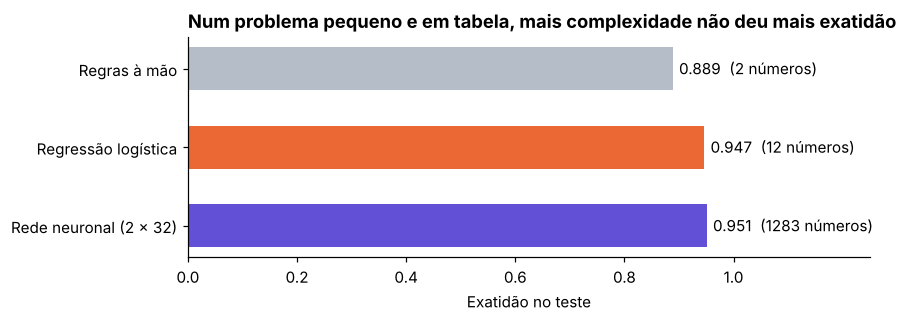

In [6]:
fig, ax = plt.subplots(figsize=(8, 2.6))
barras = ax.barh(resultados.index, resultados["exatidão no teste"], color=[CINZA, LARANJA, VIOLETA], height=0.55)
ax.bar_label(barras, labels=[f"{v:.3f}  ({n} números)" for v, n in zip(resultados["exatidão no teste"], resultados["números ajustados"])], padding=4)
ax.set_xlim(0, 1.25)
ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.invert_yaxis()
ax.set_xlabel("Exatidão no teste")
ax.set_title("Num problema pequeno e em tabela, mais complexidade não deu mais exatidão")
plt.show()

Três observações:

- As regras à mão, com dois limiares escolhidos por quem conhece as variedades, ficam seis pontos abaixo dos modelos aprendidos. São uma boa linha de base, e mostram quanto vale aprender com os dados.
- A rede neuronal ajusta cerca de cem vezes mais números do que a regressão logística e acerta em **mais um lote** em 225. É uma diferença sem significado. Em dados tabulares com poucos atributos, é o resultado habitual.
- A vantagem das redes profundas aparece quando os atributos não vêm prontos: numa fotografia de azeitonas, ninguém nos dá o peso e o comprimento, e a rede tem de aprender a extrair o que interessa a partir dos píxeis.

Uma nota sobre a comparação: o scikit-learn regulariza a regressão logística por omissão (`C=1`). Com três atributos e centenas de exemplos, essa regularização é excessiva, e por isso usámos `C=100`. Com o valor por omissão, a regressão logística fica cerca de dois pontos abaixo, e pareceria que a rede é melhor quando a diferença está apenas num hiperparâmetro. Comparar modelos de forma justa exige afinar todos; o módulo 3 explica a regularização.

A escolha da abordagem depende do problema e não da moda. As redes neuronais são tratadas no módulo 13 e, de raiz, em [Redes neuronais com NumPy](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_04_Redes_Neuronais_NumPy.ipynb).

## Os tipos de aprendizagem

O que distingue os tipos de aprendizagem é a **informação que o sistema recebe** sobre o que está certo.

| Tipo | O que o sistema recebe | Pergunta típica | Exemplo no lagar |
| --- | --- | --- | --- |
| **Supervisionada** | exemplos com a resposta certa (o alvo) | «Qual é o valor ou a classe deste caso?» | prever o rendimento; confirmar a variedade |
| **Não supervisionada** | exemplos sem resposta | «Que estrutura existe nestes dados?» | agrupar lotes ou produtores parecidos |
| **Por reforço** | uma recompensa depois de cada ação que escolhe | «Que ação devo tomar agora?» | escolher o programa de extração de cada lote |

### Supervisionada

É o tipo mais usado e o centro deste tutorial. Tem duas tarefas, que reviste no capítulo 1: **regressão**, quando o alvo é um número (o rendimento), e **classificação**, quando é uma categoria (a variedade).

### Não supervisionada

Aqui não há alvo. Há três tarefas principais:

- **agrupamento** (*clustering*): formar grupos de exemplos parecidos;
- **redução de dimensionalidade**: resumir muitas colunas em poucas, perdendo o mínimo de informação;
- **regras de associação**: encontrar itens que aparecem juntos, como produtos comprados na mesma compra.

Vamos esconder a coluna `variedade` e pedir ao K-Means três grupos, só com as medições dos frutos.

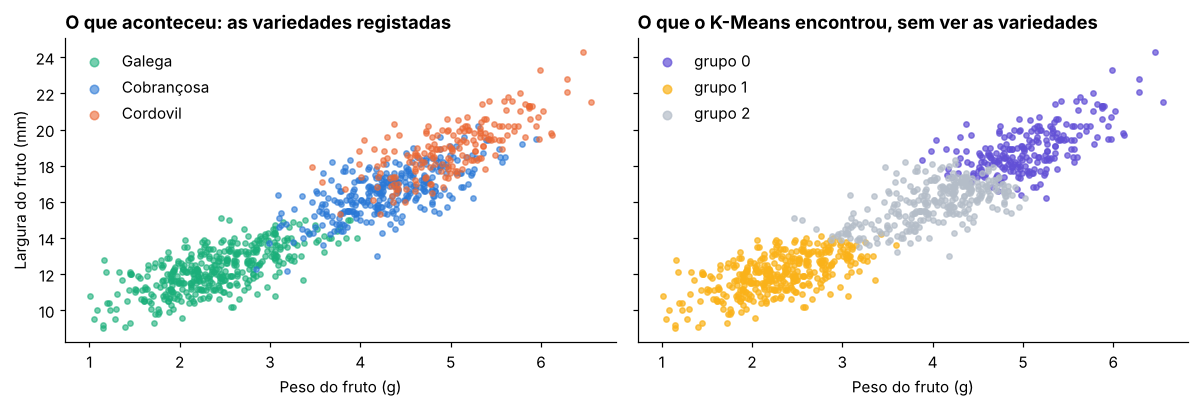

grupo do K-Means,0,1,2
variedade,,,
Cobrançosa,86,6,211
Cordovil,145,0,39
Galega,0,367,46


In [7]:
from sklearn.cluster import KMeans

escalado = StandardScaler().fit_transform(lotes[frutos])
grupo = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(escalado)

cores_variedade = {"Galega": VERDE, "Cobrançosa": AZUL, "Cordovil": LARANJA}
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True, sharey=True)
for v, cor in cores_variedade.items():
    m = lotes["variedade"] == v
    eixos[0].scatter(lotes.loc[m, "peso_g"], lotes.loc[m, "largura_mm"], s=12, color=cor, alpha=0.6, label=v)
eixos[0].set_title("O que aconteceu: as variedades registadas")
eixos[0].legend(frameon=False, markerscale=1.6)
for g, cor in zip(range(3), [VIOLETA, AVISO, CINZA]):
    m = grupo == g
    eixos[1].scatter(lotes.loc[m, "peso_g"], lotes.loc[m, "largura_mm"], s=12, color=cor, alpha=0.7, label=f"grupo {g}")
eixos[1].set_title("O que o K-Means encontrou, sem ver as variedades")
eixos[1].legend(frameon=False, markerscale=1.6)
for ax in eixos:
    ax.set_xlabel("Peso do fruto (g)")
eixos[0].set_ylabel("Largura do fruto (mm)")
plt.tight_layout()
plt.show()

pd.crosstab(lotes["variedade"], pd.Series(grupo, name="grupo do K-Means"))

O K-Means recupera quase toda a Galega, que é muito mais pequena, num só grupo. Nas outras duas variedades, que têm tamanhos parecidos, a fronteira dos grupos não coincide com a das variedades: cerca de um quarto dos lotes de cada uma fica no grupo da outra. Duas coisas a reter:

- Os grupos são numerados ao acaso. O algoritmo não sabe o que é uma variedade: quem dá nome aos grupos é a pessoa que os analisa.
- Um agrupamento não é um classificador pior. Responde a outra pergunta («que lotes são parecidos?») e usa-se quando **não existe** uma coluna com a resposta.

**Para rever a fundo:** [K-Means](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_7_aprendizagem_nao_supervisionada/01_KMeans.ipynb) · [Avaliar sem rótulos](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_7_aprendizagem_nao_supervisionada/02_Avaliar_sem_Rotulos.ipynb) · [PCA](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_7_aprendizagem_nao_supervisionada/04_PCA.ipynb). O módulo 11 deste tutorial acrescenta o DBSCAN, a deteção de anomalias e os sistemas de recomendação.

## Aprendizagem por reforço

Nos dois tipos anteriores, os dados já existem quando se começa. Na aprendizagem por reforço, um **agente** vai gerando os seus próprios dados: escolhe uma **ação**, o **ambiente** responde com uma **recompensa**, e o agente usa essa resposta para escolher melhor da próxima vez.

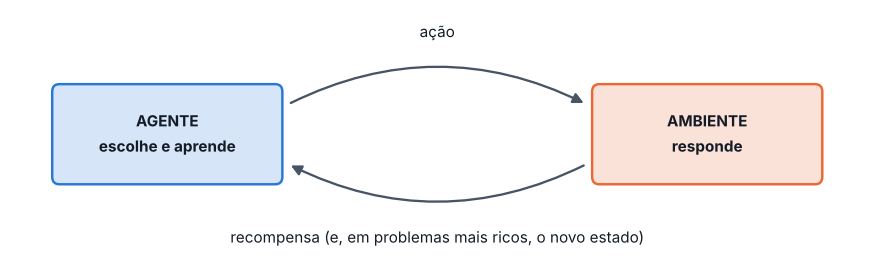

In [8]:
fig, ax = tela(12, 3.4, (10, 3))
caixa(ax, 0.6, 1.1, 3.2, 1.3, "AGENTE\nescolhe e aprende", AZUL, 10, True)
caixa(ax, 8.2, 1.1, 3.2, 1.3, "AMBIENTE\nresponde", LARANJA, 10, True)
seta(ax, (3.9, 2.15), (8.1, 2.15), connectionstyle="arc3,rad=-0.25")
seta(ax, (8.1, 1.35), (3.9, 1.35), connectionstyle="arc3,rad=-0.25")
ax.text(6, 3.05, "ação", ha="center", fontsize=10, color=TINTA)
ax.text(6, 0.3, "recompensa (e, em problemas mais ricos, o novo estado)", ha="center", fontsize=10, color=TINTA)
plt.show()

A diferença para a aprendizagem supervisionada é esta: **ninguém diz ao agente qual era a ação certa**. Ele só fica a saber quanto valeu a ação que escolheu, e nada sobre as que não escolheu.

### O problema do lagar

O lagar tem três programas de extração (A, B e C), que diferem na temperatura e no tempo de batedura. Cada lote só pode passar por um programa. Não se sabe qual dá, em média, mais azeite, e o rendimento de cada lote varia muito por outras razões.

Este é o problema de reforço mais simples que existe, conhecido por **problema das máquinas de moedas** (*multi-armed bandit*): há várias ações, cada uma com uma recompensa média desconhecida, e quer-se acumular a maior recompensa possível.

Na simulação, somos nós que fixamos as médias verdadeiras. O agente não as conhece.

In [9]:
MEDIAS = np.array([17.0, 17.6, 18.3])        # rendimento médio de cada programa (o agente não sabe isto)
DESVIO = 1.5                                  # variação de lote para lote
PROGRAMAS = ["A", "B", "C"]

rng = np.random.default_rng(1)
amostra = pd.DataFrame({p: rng.normal(m, DESVIO, 5).round(1) for p, m in zip(PROGRAMAS, MEDIAS)})
print("Cinco lotes experimentados em cada programa:")
print(amostra.to_string(index=False))
print("\nMédias observadas:", amostra.mean().round(2).to_dict())

Cinco lotes experimentados em cada programa:
   A    B    C
17.5 18.3 18.3
18.2 16.8 19.1
17.5 18.5 17.2
15.0 18.1 18.1
18.4 18.0 17.6

Médias observadas: {'A': 17.32, 'B': 17.94, 'C': 18.06}


Com cinco lotes por programa, as médias observadas podem pôr os programas pela ordem errada: a variação de lote para lote é maior do que a diferença entre programas. Experimenta mudar a semente do gerador (`default_rng(1)`) e vê como a ordem muda.

### Explorar ou aproveitar

O agente tem um dilema em cada lote:

- **aproveitar**: usar o programa que, até agora, parece o melhor;
- **explorar**: experimentar outro, para ter a certeza de que não é melhor.

Quem só aproveita pode ficar preso a um programa que teve sorte nos primeiros lotes. Quem só explora nunca usa o que aprendeu.

A estratégia **ε-gulosa** (*epsilon-greedy*) resolve o dilema com uma moeda viciada: com probabilidade ε escolhe um programa ao acaso; no resto das vezes escolhe o que tem a melhor média até ao momento. Para ter um ponto de partida, os três primeiros lotes vão um para cada programa.

In [10]:
def epsilon_guloso(epsilon, n_lotes=600, semente=0):
    """Simula uma campanha em que o programa de cada lote é escolhido pela estratégia ε-gulosa."""
    rng = np.random.default_rng(semente)
    estimativa = np.zeros(3)          # rendimento médio observado em cada programa
    vezes = np.zeros(3, dtype=int)    # número de lotes que passaram por cada programa
    escolhas = np.empty(n_lotes, dtype=int)
    recompensas = np.empty(n_lotes)
    for t in range(n_lotes):
        if t < 3:
            acao = t                                                            # primeiro, um lote em cada programa
        elif rng.random() < epsilon:
            acao = rng.integers(3)                                              # explorar
        else:
            acao = int(np.argmax(estimativa))                                   # aproveitar
        recompensa = rng.normal(MEDIAS[acao], DESVIO)                           # o ambiente responde
        vezes[acao] += 1
        estimativa[acao] += (recompensa - estimativa[acao]) / vezes[acao]       # atualizar a média desse programa
        escolhas[t], recompensas[t] = acao, recompensa
    return escolhas, recompensas, estimativa, vezes


escolhas, recompensas, estimativa, vezes = epsilon_guloso(epsilon=0.1, semente=0)
print("Lotes em cada programa:", dict(zip(PROGRAMAS, vezes.tolist())))
print("Rendimento médio estimado:", dict(zip(PROGRAMAS, estimativa.round(2).tolist())))
print(f"Rendimento médio da campanha: {recompensas.mean():.2f}% (o melhor programa dá, em média, {MEDIAS.max():.1f}%)")

Lotes em cada programa: {'A': 19, 'B': 18, 'C': 563}
Rendimento médio estimado: {'A': 17.24, 'B': 17.39, 'C': 18.18}
Rendimento médio da campanha: 18.13% (o melhor programa dá, em média, 18.3%)


A linha que atualiza a estimativa é a ideia central de toda a aprendizagem por reforço:

> nova estimativa = estimativa antiga + passo × (recompensa observada − estimativa antiga)

O agente corrige a estimativa na direção do **erro** entre o que esperava e o que recebeu. Aqui o passo é `1 / vezes`, o que dá exatamente a média das recompensas observadas.

Uma campanha é uma só experiência, e depende da sorte. Para comparar valores de ε, repetimos a simulação 300 vezes com sementes diferentes e fazemos a média.

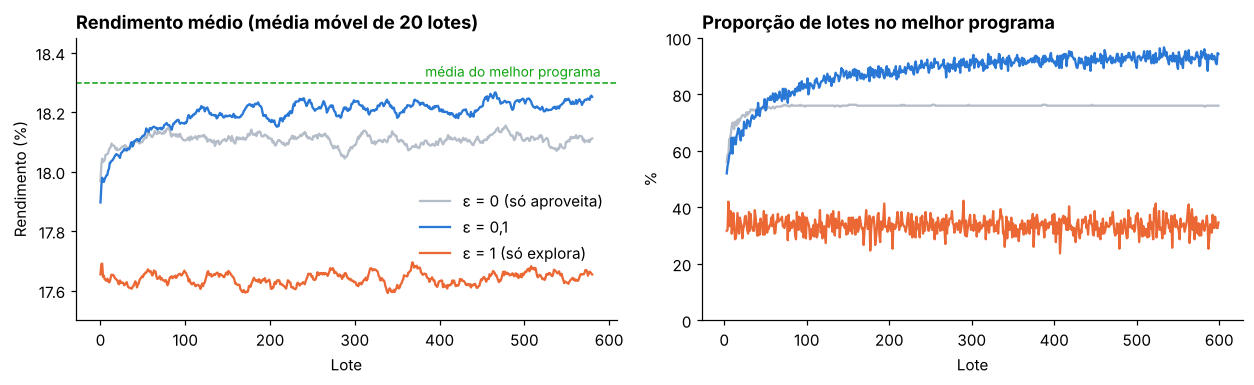

Rendimento médio da campanha, em 300 simulações:
  ε = 0 (só aproveita)   18.10%
  ε = 0,1                18.19%
  ε = 1 (só explora)     17.64%


In [11]:
def simular(epsilon, repeticoes=300, n_lotes=600):
    """Repete a campanha e devolve, para cada lote, o rendimento médio e a proporção de escolhas do melhor programa."""
    rendimento = np.zeros(n_lotes)
    escolheu_melhor = np.zeros(n_lotes)
    for semente in range(repeticoes):
        escolhas, recompensas, _, _ = epsilon_guloso(epsilon, n_lotes, semente)
        rendimento += recompensas
        escolheu_melhor += escolhas == MEDIAS.argmax()
    return rendimento / repeticoes, escolheu_melhor / repeticoes


estrategias = {"ε = 0 (só aproveita)": (0.0, CINZA), "ε = 0,1": (0.1, AZUL), "ε = 1 (só explora)": (1.0, LARANJA)}
fig, eixos = plt.subplots(1, 2, figsize=(11.5, 3.6))
resumo = {}
for nome, (eps, cor) in estrategias.items():
    rendimento, melhor = simular(eps)
    resumo[nome] = rendimento.mean()
    janela = np.ones(20) / 20
    eixos[0].plot(np.convolve(rendimento, janela, mode="valid"), color=cor, label=nome)
    eixos[1].plot(np.arange(3, len(melhor)), melhor[3:] * 100, color=cor)      # sem a ronda inicial
eixos[0].axhline(MEDIAS.max(), color=BOM, ls="--", lw=1)
eixos[0].text(590, MEDIAS.max() + 0.02, "média do melhor programa", color=BOM, ha="right", fontsize=9)
eixos[0].set_ylim(17.5, 18.45)
eixos[0].legend(frameon=False, loc="center right", bbox_to_anchor=(1.0, 0.33))
eixos[0].set_title("Rendimento médio (média móvel de 20 lotes)")
eixos[0].set_ylabel("Rendimento (%)")
eixos[1].set_title("Proporção de lotes no melhor programa")
eixos[1].set_ylabel("%")
eixos[1].set_ylim(0, 100)
for ax in eixos:
    ax.set_xlabel("Lote")
plt.tight_layout()
plt.show()

print("Rendimento médio da campanha, em 300 simulações:")
for nome, valor in resumo.items():
    print(f"  {nome:<22} {valor:.2f}%")

O que os gráficos mostram:

- **Só explorar** (ε = 1) dá o rendimento médio dos três programas (17,64%). O agente nunca usa o que aprendeu.
- **Só aproveitar** (ε = 0) decide quase tudo nos primeiros lotes. Em cerca de três quartos das campanhas acaba no melhor programa. Nas restantes fica preso a um pior, e a curva deixa de subir: um programa que teve azar no início raramente volta a ser experimentado.
- **ε = 0,1** começa pior, porque gasta lotes a explorar, e ultrapassa a estratégia anterior ao fim de algumas dezenas de lotes. Estabiliza perto dos 93% e não passa daí: continua a explorar um lote em cada dez, mesmo quando já não precisa. O exercício 3 trata desse defeito.

A diferença entre as duas estratégias no rendimento médio da campanha é pequena (18,19% contra 18,10%), porque os programas são parecidos. O que muda é o risco: com ε = 0, uma campanha em cada quatro fica num programa pior até ao fim.

O custo de explorar é real: cada lote enviado para um programa pior dá menos azeite. A aprendizagem por reforço aceita esse custo no início para ganhar mais depois.

### O que falta a este exemplo

O problema das máquinas de moedas não tem **estado**: a melhor ação é sempre a mesma. Na aprendizagem por reforço completa, a melhor ação depende da situação (a posição das peças num jogo, a velocidade de um robô), e a recompensa pode chegar muito depois da ação que a causou. As ideias de explorar, aproveitar e corrigir estimativas pelo erro mantêm-se. Este tutorial dedica-se à aprendizagem supervisionada e não supervisionada, e a aprendizagem por reforço fica por aqui.

### Entre uns e outros

Há variantes que ficam entre os três tipos:

- **Semissupervisionada:** poucos exemplos com resposta e muitos sem ela. É comum quando rotular é caro, como em imagens médicas.
- **Autossupervisionada:** o alvo é criado a partir dos próprios dados, sem ninguém a rotular. Um modelo de linguagem aprende a prever a palavra seguinte de um texto, e o texto fornece a resposta.

## Reconhecer o tipo a partir dos dados

| Se tens… | E queres… | É… |
| --- | --- | --- |
| uma coluna com a resposta, numérica | prever esse número em casos novos | supervisionada, regressão |
| uma coluna com a resposta, em categorias | prever a categoria em casos novos | supervisionada, classificação |
| só os atributos | encontrar grupos ou resumir colunas | não supervisionada |
| a possibilidade de agir e observar o resultado | escolher ações cada vez melhores | por reforço |

## Exercícios

### `Exercício 1` – Que tipo de aprendizagem?

Classifica cada situação: regressão, classificação, não supervisionada, por reforço, ou «não precisa de aprendizagem automática».

1. Estimar quantos litros de azeite vai vender uma loja na próxima semana, com as vendas dos últimos três anos.
2. Separar as azeitonas com defeito numa passadeira, com milhares de fotografias já classificadas por operadores.
3. Calcular o valor a pagar a cada produtor: quilos entregues vezes o preço fixado em assembleia.
4. Descobrir se há perfis de consumidores no registo de compras da loja, sem categorias definidas.
5. Ajustar todos os dias o preço de uma promoção na loja em linha, observando as vendas de cada dia.
6. Decidir se um lote entra na linha de azeite biológico, quando a regra é ter o certificado válido.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. **Regressão:** o alvo é um número e há histórico com a resposta.
2. **Classificação**, com imagens: é um caso típico para aprendizagem profunda.
3. **Não precisa:** é uma fórmula conhecida.
4. **Não supervisionada** (agrupamento).
5. **Por reforço:** escolhe-se uma ação (o preço), observa-se a recompensa (as vendas) e ajusta-se. É um problema de máquinas de moedas em que cada preço é uma ação.
6. **Não precisa:** é uma regra fixa, e a decisão tem de ser justificável pelo certificado.

</details>

### `Exercício 2` – Melhorar as regras à mão

As regras de `variedade_por_regras` usam dois limiares: 3,3 g e 1,27. Usa **só os dados de treino** para procurar um par de limiares melhor (por exemplo, pesos entre 2,8 e 3,8 e razões entre 1,20 e 1,34). Depois avalia as novas regras no teste. Ficaram acima da regressão logística?

In [12]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
def regras(X, limite_peso, limite_razao):
    razao = X["comprimento_mm"] / X["largura_mm"]
    return np.where(X["peso_g"] < limite_peso, "Galega", np.where(razao < limite_razao, "Cordovil", "Cobrançosa"))


melhor = (0, None, None)
for limite_peso in np.arange(2.8, 3.81, 0.1):
    for limite_razao in np.arange(1.20, 1.341, 0.01):
        exatidao = (regras(X_treino, limite_peso, limite_razao) == y_treino).mean()
        if exatidao > melhor[0]:
            melhor = (exatidao, limite_peso, limite_razao)

print(f"Melhor par no treino: peso < {melhor[1]:.1f} g, razão < {melhor[2]:.2f} (exatidão no treino: {melhor[0]:.3f})")
print(f"No teste: {(regras(X_teste, melhor[1], melhor[2]) == y_teste).mean():.3f}")
```

O melhor par no treino (3,3 g e 1,26) é quase igual ao do técnico, e no teste as regras passam de 0,889 para 0,893. Continuam abaixo da regressão logística (0,947): com dois limiares em linha reta sobre o peso e sobre a razão, não se chega mais longe.

Repara no que fizeste. Ao procurar os limiares nos dados, deixaste de ter regras escritas à mão: **treinaste um modelo** com dois parâmetros, por procura exaustiva. A forma das regras continua a vir de uma pessoa, e os números passaram a vir dos dados. É exatamente o que uma árvore de decisão faz, com a diferença de que a árvore também escolhe as perguntas (módulo 6).

</details>

### `Exercício 3` – Explorar cada vez menos

Com ε fixo, o agente continua a explorar ao mesmo ritmo até ao fim da campanha. Escreve uma variante de `epsilon_guloso` em que ε diminui com o tempo, por exemplo `epsilon = 1 / np.sqrt(t + 1)`. Compara o rendimento médio de 300 simulações com o de ε = 0,1.

In [13]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
def epsilon_decrescente(n_lotes=600, semente=0):
    rng = np.random.default_rng(semente)
    estimativa, vezes = np.zeros(3), np.zeros(3, dtype=int)
    recompensas = np.empty(n_lotes)
    for t in range(n_lotes):
        epsilon = 1 / np.sqrt(t + 1)                    # explora muito no início e cada vez menos
        if t < 3:
            acao = t
        elif rng.random() < epsilon:
            acao = rng.integers(3)
        else:
            acao = int(np.argmax(estimativa))
        recompensa = rng.normal(MEDIAS[acao], DESVIO)
        vezes[acao] += 1
        estimativa[acao] += (recompensa - estimativa[acao]) / vezes[acao]
        recompensas[t] = recompensa
    return recompensas


decrescente = np.mean([epsilon_decrescente(semente=s).mean() for s in range(300)])
fixo = np.mean([epsilon_guloso(0.1, semente=s)[1].mean() for s in range(300)])
print(f"ε decrescente: {decrescente:.2f}% | ε = 0,1: {fixo:.2f}%")
```

As duas estratégias ficam muito próximas nesta campanha de 600 lotes. O ε decrescente explora mais no início, quando as estimativas são fracas, e menos no fim, e a vantagem cresce com o número de lotes: numa campanha mais longa, o ε fixo continua a perder um lote em cada dez. Experimenta com `n_lotes=5000`.

</details>

### `Exercício 4` – Dois grupos em vez de três

Repete o agrupamento com `n_clusters=2` e cruza os grupos com a variedade. O que juntou o K-Means? Faz sentido?

In [14]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
grupo2 = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(escalado)
print(pd.crosstab(lotes["variedade"], pd.Series(grupo2, name="grupo")))
```

Com dois grupos, o K-Means separa a Galega das outras duas, que ficam juntas. Faz sentido: nas medições dos frutos, a diferença entre a Galega e as restantes é muito maior do que a diferença entre a Cobrançosa e a Cordovil. O algoritmo agrupa pelo que é mais diferente nas colunas que recebe, e isso pode ou não coincidir com as categorias que interessam a quem o usa.

</details>

## Verifica o que aprendeste

- [ ] Sei explicar a relação entre inteligência artificial, aprendizagem automática e aprendizagem profunda.
- [ ] Sei dar um exemplo de inteligência artificial que não aprende com dados.
- [ ] Sei em que tipo de dados a aprendizagem profunda tem vantagem, e porque não é a escolha por omissão em tabelas pequenas.
- [ ] Sei distinguir aprendizagem supervisionada, não supervisionada e por reforço pela informação que o sistema recebe.
- [ ] Sei explicar o dilema entre explorar e aproveitar.
- [ ] Sei implementar a estratégia ε-gulosa e explicar a regra de atualização da estimativa.
- [ ] Sei dizer o que são a aprendizagem semissupervisionada e a autossupervisionada.

## Leitura recomendada

- https://scikit-learn.org/stable/tutorial/machine_learning_map/index.html
- R. Sutton e A. Barto, *Reinforcement Learning: An Introduction*, 2.ª edição, capítulo 2 (o problema das máquinas de moedas): http://incompleteideas.net/book/the-book-2nd.html
- https://en.wikipedia.org/wiki/Multi-armed_bandit